# Lab 02-09 · Systems of Linear ODEs and the Matrix Exponential

Companion to chapter [02-09](../../chapters/02-09-systems-of-odes-and-matrix-exponential.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.integrate import solve_ivp
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
np.set_printoptions(precision=5, suppress=True)

## Part 1 — Three ways to the same answer

The coupled capacitors of Example 02-09.2 (time in units of τ).

In [2]:
A = np.array([[-2.0, 1.0], [1.0, -2.0]])
x0 = np.array([1.0, 0.0])
t_eval = np.array([0.25, 0.5493, 1.0, 2.0])

w, V = np.linalg.eig(A)
c = np.linalg.solve(V, x0)
eig_sol = np.array([V @ (c * np.exp(w * t)) for t in t_eval])
expm_sol = np.array([expm(A * t) @ x0 for t in t_eval])
ivp = solve_ivp(lambda t, x: A @ x, (0, 2), x0, t_eval=t_eval, rtol=1e-11, atol=1e-13)
for k, t in enumerate(t_eval):
    print(f"t = {t:6.4f}: eigenvectors {eig_sol[k]}, expm {expm_sol[k]}, solve_ivp {ivp.y[:, k]}")
print("max difference:", np.max(np.abs(eig_sol - expm_sol)), np.max(np.abs(expm_sol - ivp.y.T)))

t = 0.2500: eigenvectors [0.62558+0.j 0.15322+0.j], expm [0.62558 0.15322], solve_ivp [0.62558 0.15322]
t = 0.5493: eigenvectors [0.3849 +0.j 0.19245+0.j], expm [0.3849  0.19245], solve_ivp [0.3849  0.19245]
t = 1.0000: eigenvectors [0.20883+0.j 0.15905+0.j], expm [0.20883 0.15905], solve_ivp [0.20883 0.15905]
t = 2.0000: eigenvectors [0.06891+0.j 0.06643+0.j], expm [0.06891 0.06643], solve_ivp [0.06891 0.06643]
max difference: 1.4432899320127035e-15 2.31717423027078e-13


## Part 2 — How not to compute the exponential

**🔮 Predict:** sum the Taylor series of $e^{x}$ at $x = -20$ in double precision until the terms are negligible. How many correct significant digits will you get? (The true value is about $2\times10^{-9}$, and the largest term is about $4\times10^7$.)

In [3]:
def taylor_exp(x, n_terms=150):
    term, total = 1.0, 1.0
    for k in range(1, n_terms):
        term *= x / k
        total += term
    return total

x = -20.0
approx, true = taylor_exp(x), math.exp(x)
print(f"Taylor sum: {approx:.6e}   true: {true:.6e}   relative error: {abs(approx - true) / true:.2e}")
print("largest term magnitude:", max(abs(x)**k / math.factorial(k) for k in range(60)))

# The matrix version has the same problem, and scaling and squaring fixes it
M = np.array([[-20.0, 1.0], [0.0, -20.0]])
series = np.eye(2); term = np.eye(2)
for k in range(1, 150):
    term = term @ M / k
    series = series + term
E = expm(M)
for (i, j) in ((0, 0), (0, 1)):
    print(f"entry ({i+1},{j+1}): series {series[i, j]: .4e}   expm {E[i, j]: .4e}   exact {[math.exp(-20), math.exp(-20)][j]: .4e}")

Taylor sum: 6.147562e-09   true: 2.061154e-09   relative error: 1.98e+00
largest term magnitude: 43099804.12182177
entry (1,1): series  5.6219e-09   expm  2.0612e-09   exact  2.0612e-09
entry (1,2): series  2.4111e-09   expm  2.0612e-09   exact  2.0612e-09


Huge terms of alternating sign cancel, and their rounding errors (about $10^{-16}$ of $4\times10^7$, roughly $10^{-8}$) swamp a true answer of $2\times10^{-9}$. Scaling and squaring avoids this by working with $\mathbf{M}/2^s$, whose series is well behaved, and then squaring.

## Part 3 — Phase portraits

**🔮 Predict:** take the spiral $\begin{bmatrix} a & -4 \\ 1 & a\end{bmatrix}$ and raise $a$ from −1 through 0 to +0.3. What happens to the trajectories, and at what trace?

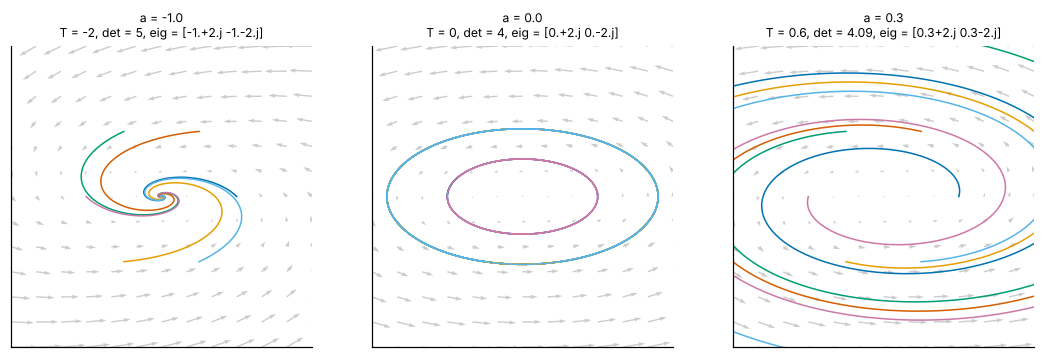

center x'' = -4x: period = 3.1415926535897922 s


In [4]:
def portrait(A, ax, title, tend=6):
    g = np.linspace(-1.2, 1.2, 13); X, Y = np.meshgrid(g, g)
    ax.quiver(X, Y, A[0, 0]*X + A[0, 1]*Y, A[1, 0]*X + A[1, 1]*Y, color="0.8", angles="xy")
    for th in np.linspace(0, 2*np.pi, 7)[:-1]:
        x0 = 0.6 * np.array([np.cos(th), np.sin(th)])
        tr = np.array([expm(A*t) @ x0 for t in np.linspace(0, tend, 400)])
        tr = tr[np.all(np.abs(tr) < 1.3, axis=1)]
        ax.plot(tr[:, 0], tr[:, 1], lw=1)
    T, D = np.trace(A), np.linalg.det(A)
    ax.set_title(f"{title}\nT = {T:.2g}, det = {D:.3g}, eig = {np.round(np.linalg.eigvals(A), 2)}", fontsize=8)
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, a in zip(axes, (-1.0, 0.0, 0.3)):
    portrait(np.array([[a, -4.0], [1.0, a]]), ax, f"a = {a}")
plt.show()
A4 = np.array([[0.0, 1.0], [-4.0, 0.0]])
print("center x'' = -4x: period =", 2 * math.pi / abs(np.linalg.eigvals(A4)[0].imag), "s")

## Part 4 — Thermal transients and Foster models

Example 02-09.5: die and heat sink, 10 W step. Extract the Foster model from the eigen-decomposition and plot $Z_{th}$ the way datasheets do.

steady state (die, sink): [20. 15.] K
time constants: [ 0.96106 78.03894] s   Foster R: [0.46158 1.53842] K/W   sum: 2.000000000000001
Zth(  0.01 s) = 0.00498 K/W  -> die rise for 10 W: 0.0498 K
Zth(   0.1 s) = 0.04758 K/W  -> die rise for 10 W: 0.4758 K
Zth(     1 s) = 0.31811 K/W  -> die rise for 10 W: 3.1811 K
Zth(    10 s) = 0.64660 K/W  -> die rise for 10 W: 6.4660 K
Zth(   100 s) = 1.57287 K/W  -> die rise for 10 W: 15.7287 K
largest stable forward-Euler step for this model: 1.922117309827458 s


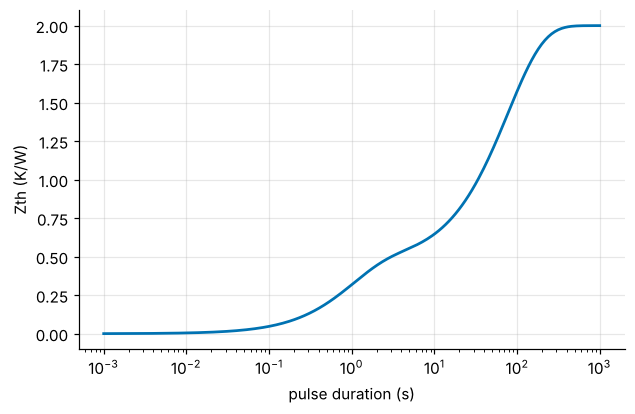

In [5]:
Rdh, Rha, Cd, Ch, Pw = 0.5, 1.5, 2.0, 50.0, 10.0
A = np.array([[-1/(Rdh*Cd), 1/(Rdh*Cd)], [1/(Rdh*Ch), -(1/Rdh + 1/Rha)/Ch]])
B = np.array([1/Cd, 0.0])
xss = -np.linalg.solve(A, B * Pw)
w, V = np.linalg.eig(A); w, V = np.real(w), np.real(V)
c = np.linalg.solve(V, -xss)
R_foster = -(c * V[0]) / Pw
tau = -1 / w
print("steady state (die, sink):", xss, "K")
print("time constants:", tau, "s   Foster R:", R_foster, "K/W   sum:", R_foster.sum())
Z = lambda t: np.sum(R_foster * (1 - np.exp(-t / tau)))
for t in (0.01, 0.1, 1, 10, 100):
    print(f"Zth({t:>6} s) = {Z(t):.5f} K/W  -> die rise for 10 W: {10*Z(t):.4f} K")
print("largest stable forward-Euler step for this model:", 2 / np.max(np.abs(w)), "s")
tl = np.logspace(-3, 3, 300)
plt.semilogx(tl, [Z(t) for t in tl]); plt.xlabel("pulse duration (s)"); plt.ylabel("Zth (K/W)"); plt.show()

## Part 5 — Exact sampling versus forward Euler

**🔮 Predict:** for the coupled capacitors (τ = 1 ms), at what step size does forward Euler first go unstable?

T = 0.25 ms: exact z = [0.7788+0.j 0.4724+0.j], Euler = [0.75+0.j 0.25+0.j], Euler stable: True
T = 0.50 ms: exact z = [0.2231+0.j 0.6065+0.j], Euler = [ 0.5+0.j -0.5+0.j], Euler stable: True
T = 0.60 ms: exact z = [0.5488+0.j 0.1653+0.j], Euler = [ 0.4+0.j -0.8+0.j], Euler stable: True
T = 0.66 ms: exact z = [0.5169+0.j 0.1381+0.j], Euler = [ 0.34+0.j -0.98+0.j], Euler stable: True
T = 0.67 ms: exact z = [0.5117+0.j 0.134 +0.j], Euler = [ 0.33+0.j -1.01+0.j], Euler stable: False
T = 0.70 ms: exact z = [0.4966+0.j 0.1225+0.j], Euler = [ 0.3+0.j -1.1+0.j], Euler stable: False
T = 1.00 ms: exact z = [0.3679+0.j 0.0498+0.j], Euler = [ 0.+0.j -2.+0.j], Euler stable: False


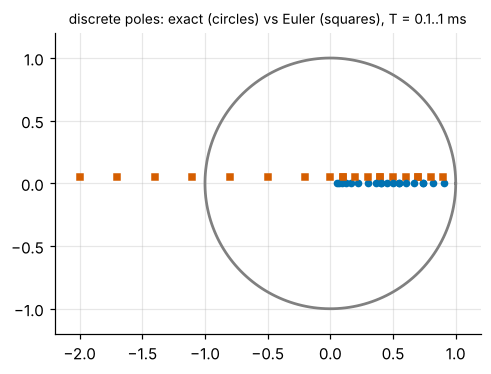

In [6]:
A = np.array([[-2.0, 1.0], [1.0, -2.0]])   # time in ms (tau = 1 ms)
for T in (0.25, 0.5, 0.6, 0.66, 0.67, 0.7, 1.0):
    ez = np.linalg.eigvals(expm(A * T)); ee = np.linalg.eigvals(np.eye(2) + A * T)
    print(f"T = {T:4.2f} ms: exact z = {np.round(ez, 4)}, Euler = {np.round(ee, 4)}, "
          f"Euler stable: {np.all(np.abs(ee) < 1)}")

fig, ax = plt.subplots(figsize=(5, 5))
th = np.linspace(0, 2*np.pi, 200); ax.plot(np.cos(th), np.sin(th), color="0.5")
for T in np.linspace(0.1, 1.0, 10):
    ax.plot(np.exp(np.array([-1, -3]) * T), [0, 0], "o", color="C0", ms=4)
    ax.plot(1 + np.array([-1, -3]) * T, [0.05, 0.05], "s", color="C1", ms=4)
ax.set_xlim(-2.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal")
ax.set_title("discrete poles: exact (circles) vs Euler (squares), T = 0.1..1 ms", fontsize=9); plt.show()

## Part 6 — A state-space sequence layer

Problem 02-09.15: a one-state layer $h_k = \bar{a}h_{k-1} + \bar{b}x_k$ with $\bar{a} = e^{-\Delta/\tau}$. A larger Δ means faster forgetting.

**🔮 Predict:** with τ/Δ = 20, how many steps until an impulse has decayed to 1%?

tau/Delta =   5: decays to 1% after 24 steps  (formula (tau/Delta) ln 100 = 23.03)
tau/Delta =  20: decays to 1% after 93 steps  (formula (tau/Delta) ln 100 = 92.10)
tau/Delta =  50: decays to 1% after 231 steps  (formula (tau/Delta) ln 100 = 230.26)


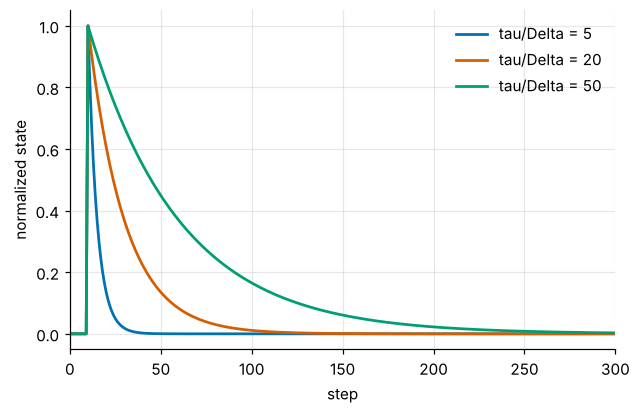

In [7]:
def ssm_layer(x, tau_over_delta):
    a_bar = math.exp(-1 / tau_over_delta); b_bar = 1 - a_bar
    h, out = 0.0, []
    for xk in x:
        h = a_bar * h + b_bar * xk
        out.append(h)
    return np.array(out)

x = np.zeros(400); x[10] = 1.0
for r in (5, 20, 50):
    y = ssm_layer(x, r)
    k1 = np.argmax(y[11:] < 0.01 * y[10]) + 1
    print(f"tau/Delta = {r:3d}: decays to 1% after {k1} steps  (formula (tau/Delta) ln 100 = {r*math.log(100):.2f})")
    plt.plot(y / y.max(), label=f"tau/Delta = {r}")
plt.xlim(0, 300); plt.xlabel("step"); plt.ylabel("normalized state"); plt.legend(); plt.show()

## Part 7 — ngspice

From the repository root, run `python tools/run_spice.py 02-09`:

- `coupled_rc.cir`: Example 02-09.2 (peak of $v_2$: 0.1925 V at 0.5493 ms) and Problem 02-09.9 (0.1577 V at 1 ms);
- `thermal_analog.cir`: Example 02-09.5 as an electrical analog (3.181, 6.466 and 15.73 V, read as K, at 1, 10 and 100 s);
- `foster_pulse.cir`: Problem 02-09.14's Foster network with a 50 W, 10 ms pulse (14.86 K at the end of the pulse).

## Your turn

1. In Part 4, double the heat sink's capacity $C_h$. Which time constant changes most, and which Foster resistance?
2. In Part 5, replace forward Euler by backward Euler, $\mathbf{A}_d = (\mathbf{I} - \mathbf{A}T)^{-1}$. Show that it is stable for every $T$, and compare its accuracy with the exact $e^{\mathbf{A}T}$.
3. Build the 4-state coupled-resonator model of Problem 02-09.13 and simulate the energy exchange when only resonator 1 starts charged.